# Experiment 09 — Global Average Pooling (GAP)

In this experiment, we investigate the effect of Global Average Pooling (GAP) on the CNN's performance and overfitting. Instead of flattening the entire feature maps and passing a large number of features to the fully connected layers, GAP computes the average value of each feature map and reduces it to a single value.

The goal is to examine whether reducing the number of parameters and the capacity of the classifier can reduce overfitting and improve generalization on the validation set.

All experimental conditions are kept fixed, and only the use of GAP is changed.

In [21]:
import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter

from torch.optim import Adam
from torchvision import transforms

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)

### Configuration

In [22]:
SEED = 42
set_seed(SEED)
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 1e-3
NUM_CLASSES = 8


config_gap = {
    "experiment": "GAP",
    "architecture": "SimpleCNN",
    "num_classes": NUM_CLASSES,
    "use_gap": True,
    "dropout": 0.0,
    "loss": "CrossEntropyLoss",
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": 0,
    "epochs": EPOCHS,
    "seed": SEED
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


### Paths

In [23]:
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"


print("Training directory:", MERGED_TRAIN_DIR)


print("Training directory exists:", MERGED_TRAIN_DIR.exists())

Training directory: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\merged_train
Training directory exists: True


### Transforms as the Baseline Model

In [24]:
baseline_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### Create Train/Validation Datasets

In [25]:
train_dataset, val_dataset, train_indices, val_indices,class_to_idx= \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform=baseline_transform,
        val_transform=baseline_transform,
        test_size=0.2,
        seed=SEED
    )

### Class Names

In [26]:
full_dataset = datasets.ImageFolder(
    MERGED_TRAIN_DIR
)

class_names = full_dataset.classes
class_to_idx = full_dataset.class_to_idx

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "->", class_name)

print("\nNumber of classes:", len(class_names))

Classes:
0 -> ambulance
1 -> autobus
2 -> kamyun
3 -> kamyunet
4 -> minibus
5 -> savari
6 -> taxi
7 -> vanet

Number of classes: 8


### Data Loaders

In [27]:
train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle_train=True
)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 85
Number of validation batches: 22


### Model With Gap

In [28]:
model_gap = SimpleCNN(
    num_classes=NUM_CLASSES,
    dropout=0.0,
    use_gap=True
).to(DEVICE)

criterion_gap = nn.CrossEntropyLoss()

optimizer_gap = torch.optim.AdamW(
    model_gap.parameters(),
    lr=1e-3,
    weight_decay=0
)

### Train Model

In [29]:
history_gap, best_val_acc_gap = train_model(
    model=model_gap,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_gap,
    optimizer=optimizer_gap,
    device=DEVICE,
    epochs=EPOCHS,
    model_name="gap",
    class_to_idx=class_to_idx,
    seed=SEED,
    config=config_gap,
    early_stopping=True,
    min_delta=0.001,
    patience=3
)

Epoch [1/50] Train Loss: 1.9828 --- Train Acc: 0.2290 --- Val Loss: 1.8512 --- Val Acc: 0.3314 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [2/50] Train Loss: 1.8144 --- Train Acc: 0.3027 --- Val Loss: 1.7874 --- Val Acc: 0.3417 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [3/50] Train Loss: 1.7304 --- Train Acc: 0.3481 --- Val Loss: 1.6849 --- Val Acc: 0.3652 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [4/50] Train Loss: 1.6584 --- Train Acc: 0.3809 --- Val Loss: 1.5921 --- Val Acc: 0.4212 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [5/50] Train Loss: 1.5973 --- Train Acc: 0.4027 --- Val Loss: 1.5603 --- Val Acc: 0.4227 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [6/50] Train Loss: 1.5738 --- Train Acc: 0.3945 --- Val Loss: 1.5343 --- Val Acc: 0.4345 --- LR: 0.001000
  → Validation accuracy improved. Checkpoint saved.
Epoch [7/50] Tra

### Training Curves

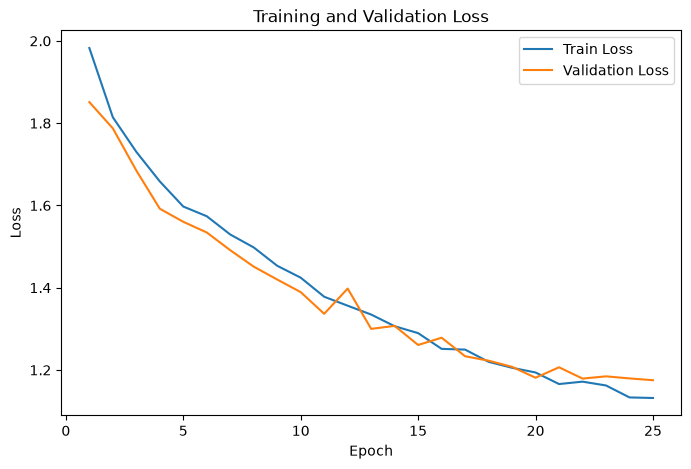

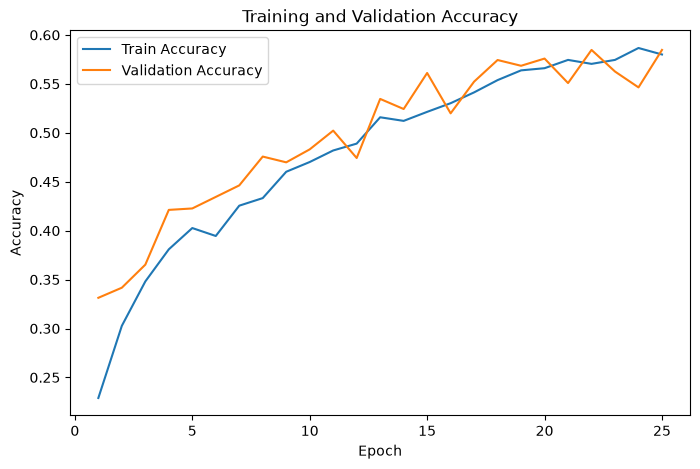

In [30]:
plot_training_history(history=history_gap)

### Best Epoch

In [31]:
best_epoch = np.argmax(
    history_gap["val_accuracy"]
) + 1

print("Best epoch:", best_epoch)
print("Best validation accuracy:", best_val_acc_gap)

Best epoch: 22
Best validation accuracy: 0.5846833578792342


### Load Best CheckPoint

In [32]:
checkpoint_path = (
    PROJECT_DIR
    / "checkpoints"
    / "gap_best.pt"
)


checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

model_gap.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation accuracy:",
    checkpoint["val_accuracy"]
)

Best epoch: 22
Best validation accuracy: 0.5846833578792342


### Validation Prediction

In [33]:
true_labels, predictions = get_predictions(
    model=model_gap,
    loader=val_loader,
    device=DEVICE
)

print("Number of  validation predictions:", len(predictions))
correct = (true_labels == predictions).sum()
print("Number of correct validation predictions:", correct)
accuracy = correct / len(predictions)
print("Validation accuracy:", accuracy)

Number of  validation predictions: 679
Number of correct validation predictions: 397
Validation accuracy: 0.5846833578792342


### Classification Report

In [34]:
report = get_classification_report(
    model=model_gap,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

              precision    recall  f1-score   support

   ambulance     0.6061    0.5556    0.5797        72
     autobus     0.5049    0.5532    0.5279        94
      kamyun     0.6944    0.5000    0.5814       100
    kamyunet     0.3448    0.5495    0.4237        91
     minibus     0.6176    0.5122    0.5600        82
      savari     0.6372    0.7200    0.6761       100
        taxi     0.8198    0.9192    0.8667        99
       vanet     0.0000    0.0000    0.0000        41

    accuracy                         0.5847       679
   macro avg     0.5281    0.5387    0.5269       679
weighted avg     0.5706    0.5847    0.5705       679



### CM and Normalized CM

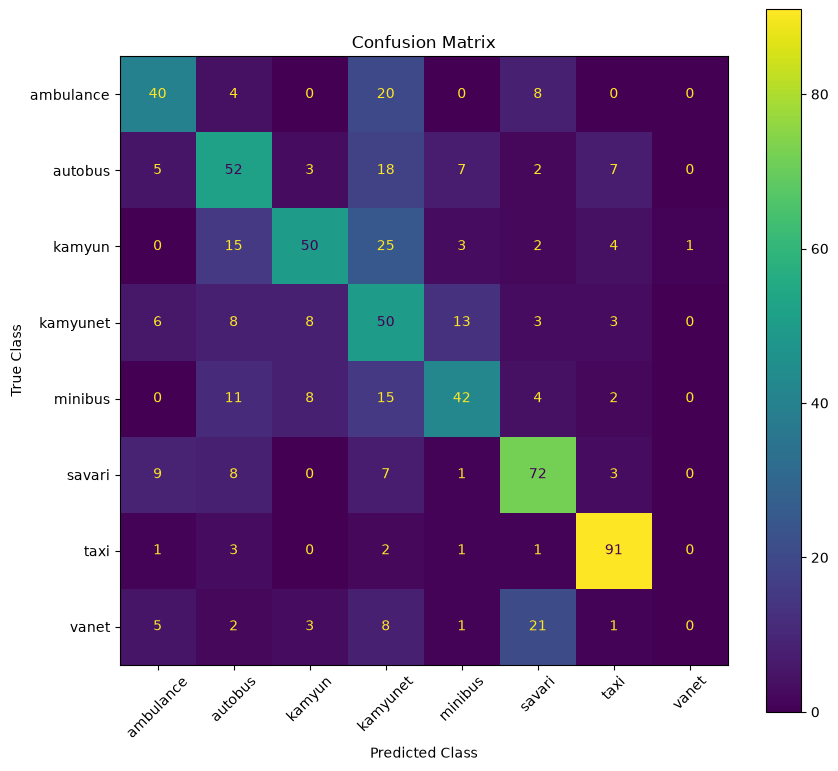

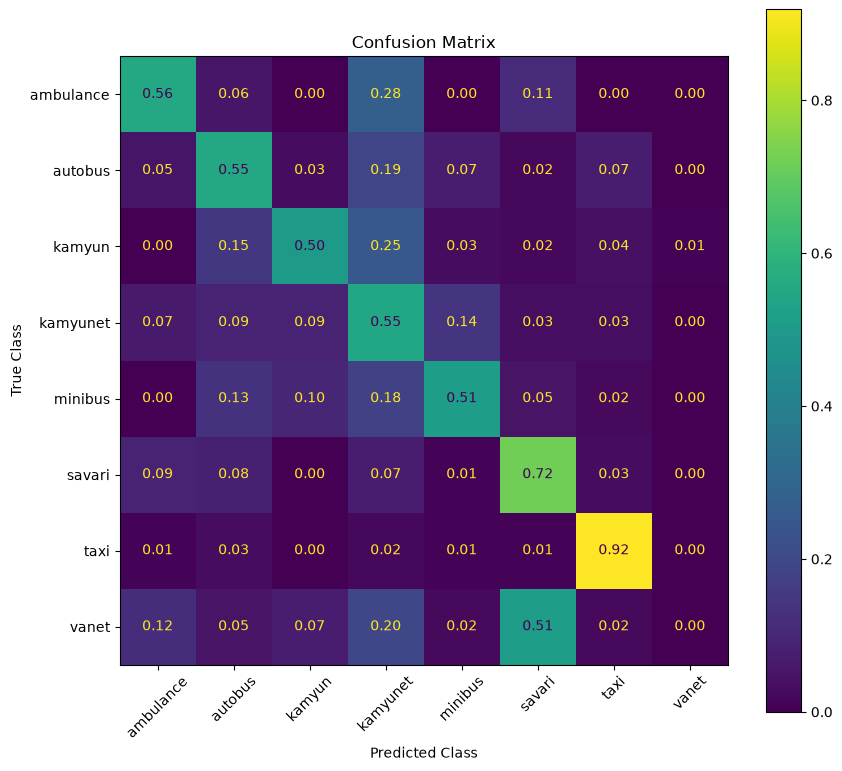

In [35]:
cm = plot_confusion_matrix(
    model=model_gap,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE
)

cm_normalized = plot_confusion_matrix(
    model=model_gap,
    loader=val_loader,
    class_names=class_names,
    device=DEVICE,
    normalize="true"
)

### Train/Validation Gap

In [36]:
best_epoch = np.argmax(
    history_gap["val_accuracy"]
)

best_train_accuracy = history_gap["train_accuracy"][best_epoch]
best_val_accuracy = history_gap["val_accuracy"][best_epoch]

print("Best Epoch:", best_epoch + 1)

print(
    "Best Train Accuracy:",
    best_train_accuracy
)

print(
    "Best Validation Accuracy:",
    best_val_accuracy
)

print(
    "Train-Validation Gap:",
    best_train_accuracy - best_val_accuracy
)

Best Epoch: 22
Best Train Accuracy: 0.5704277286135693
Best Validation Accuracy: 0.5846833578792342
Train-Validation Gap: -0.014255629265664926


### Gap Final Results

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

baseline_accuracy = accuracy_score(
    true_labels,
    predictions
)

baseline_precision = precision_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

baseline_recall = recall_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

baseline_f1 = f1_score(
    true_labels,
    predictions,
    average="macro",
    zero_division=0
)

print("Baseline Validation Results")
print("---------------------------")
print("Accuracy:", baseline_accuracy)
print("Macro Precision:", baseline_precision)
print("Macro Recall:", baseline_recall)
print("Macro F1:", baseline_f1)

Baseline Validation Results
---------------------------
Accuracy: 0.5846833578792342
Macro Precision: 0.528102753235032
Macro Recall: 0.5386980794388683
Macro F1: 0.526934511718099
